# AI SCI 210 - Week 4 Thursday

## Removing old Codespaces to prevent storage consumption

I received an alert this morning that I had used 90% of my Codespace storage for the month.  (Storage for Codespaces is calculated not just in terms of space used, but also the time stored.)  I think the main problem is that I had not been deleting Codespaces when I was finished with them.  (Deleting a Codespace doesn't affect the corresponding Repository, as long as you've synced/pushed the changes in your Codespace to GitHub using Save/Stage/Commit/Sync.)  I recommend deleting the Codespaces you plan to no longer use (probably everything except Unit 1 and this week's Homework).  You can see your current codespaces [here](https://github.com/codespaces).

Another option is to work locally on your own computer, like what I believe you're doing in AISCI 290A.

## Logistic Regression in scikit-learn

Here is the same setup as from Tuesday.  Our goal is to use Logistic Regression to predict whether a car has at least 25mpg using "weight" and "horsepower" as predictors.

In [1]:
import seaborn as sns
from sklearn.linear_model import LogisticRegression

In [2]:
df = sns.load_dataset("mpg")
df = df.dropna(axis=0).copy()
df["target"] = (df["mpg"] >= 25)

In [3]:
clf = LogisticRegression()

In [4]:
clf.fit(df[["weight", "horsepower"]], df["target"])

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

* Draw a scatterplot where you color the points according to our predictions.  Can you recognize the linear decision boundary?

<Axes: xlabel='weight', ylabel='horsepower'>

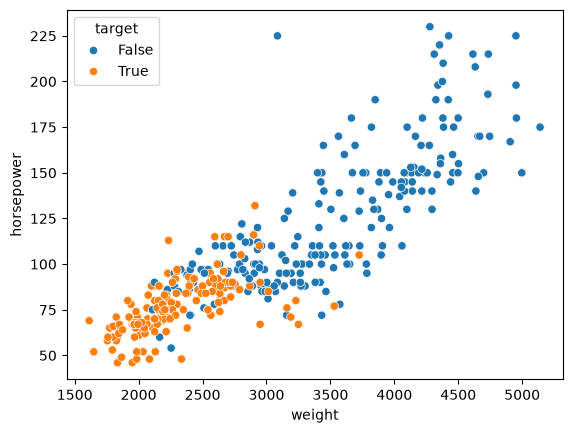

In [5]:
# actual values, not the predictions
sns.scatterplot(
    x="weight",
    y="horsepower",
    hue="target",
    data=df
)

In [6]:
df["pred"] = clf.predict(df[["weight", "horsepower"]])

<Axes: xlabel='weight', ylabel='horsepower'>

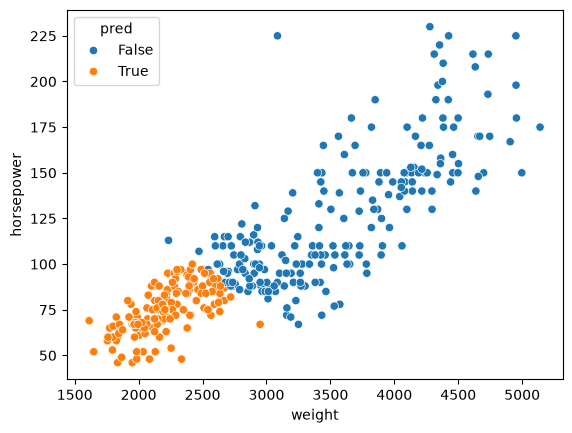

In [7]:
# predicted values
sns.scatterplot(
    x="weight",
    y="horsepower",
    hue="pred",
    data=df
)

* Draw a scatterplot where you color the points according to whether we predict at least a 95% probability of being 25 mpg (or higher).

In [12]:
# broadcasting to produce a Boolean array
df["pred95"] = clf.predict_proba(df[["weight", "horsepower"]])[:, 1] > 0.95

<Axes: xlabel='weight', ylabel='horsepower'>

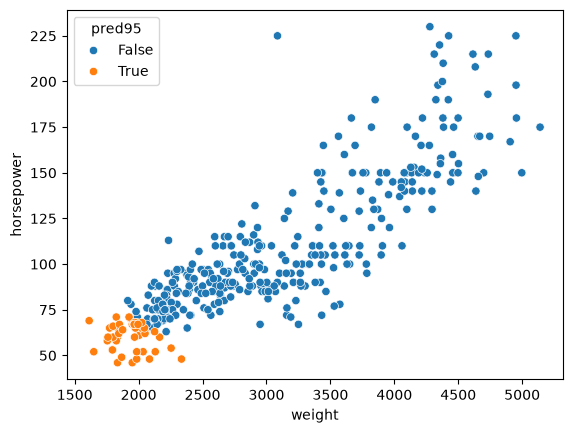

In [ ]:
# predicted values
# Note that the two decision boundaries we've seen look parallel (they are)
sns.scatterplot(
    x="weight",
    y="horsepower",
    hue="pred95",
    data=df
)

* What is the slope of both these decision boundaries?  Try to estimate it from the pictures, then try to calculate it exactly (up to numerical precision of course).

In [14]:
# estimate
-70/1000

-0.07

In [16]:
clf.coef_[0]

array([-0.00282091, -0.05384914])

In [17]:
m1, m2 = clf.coef_[0]

In [18]:
m1

np.float64(-0.0028209103312978796)

In [19]:
m2

np.float64(-0.0538491386021622)

In [ ]:
# exact slope (up to numerical precision)
-m1/m2

np.float64(-0.052385430937693996)

## Splitting the data into a training set and a test set

* Using scikit-learn's `train_test_split`, fit the classifier on 80% of the data and compare performance on the remaining 20%.
* Why would we typically not be too concerned about overfitting in this particular case?

In [21]:
from sklearn.model_selection import train_test_split

In [22]:
X = df[["weight", "horsepower"]]
y = df["target"]

In [48]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [49]:
df.shape

(392, 12)

In [50]:
X_train.shape

(313, 2)

In [51]:
X_train

,weight,horsepower
260,3620,110.0
184,2572,92.0
174,2984,97.0
64,4135,150.0
344,1875,64.0
...,...,...
72,3892,150.0
107,2789,100.0
272,2855,85.0
352,2380,65.0


In [52]:
clf2 = LogisticRegression()

In [53]:
clf2.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [54]:
clf2.score(X_train, y_train)

0.8626198083067093

In [55]:
# Did better on the unseen test data.  Surprising!
# Definitely a sign that we're not overfitting
clf2.score(X_test, y_test)

0.8860759493670886

## Feature Engineering

* Add a new column to the DataFrame corresponding to weight times horsepower.

In [56]:
df["wh"] = df["weight"]*df["horsepower"]

* Fit a new LogisticRegression model to our data using only this new column as predictor.

In [57]:
clf3 = LogisticRegression()

In [58]:
clf3.fit(df[["wh"]], df["target"])

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

* How does our accuracy compare with this new model?

In [59]:
clf3.score(df[["wh"]], df["target"])

0.875

* What does the "linear" decision boundary look like in this case?

In [60]:
import numpy as np
import pandas as pd

In [81]:
# fake data
n = 40
x = np.linspace(1500, 5000, n)
y = np.linspace(50, 200, n)

In [82]:
from itertools import product

In [83]:
fake_data = list(product(x,y))

In [84]:
len(fake_data)

1600

In [85]:
df_fake = pd.DataFrame(fake_data, columns=["weight", "horsepower"])

In [86]:
df_fake

,weight,horsepower
0,1500.0,50.000000
1,1500.0,53.846154
2,1500.0,57.692308
3,1500.0,61.538462
4,1500.0,65.384615
...,...,...
1595,5000.0,184.615385
1596,5000.0,188.461538
1597,5000.0,192.307692
1598,5000.0,196.153846


In [87]:
df_fake["wh"] = df_fake["weight"]*df_fake["horsepower"]

In [88]:
df_fake["pred"] = clf3.predict(df_fake[["wh"]])

<Axes: xlabel='weight', ylabel='horsepower'>

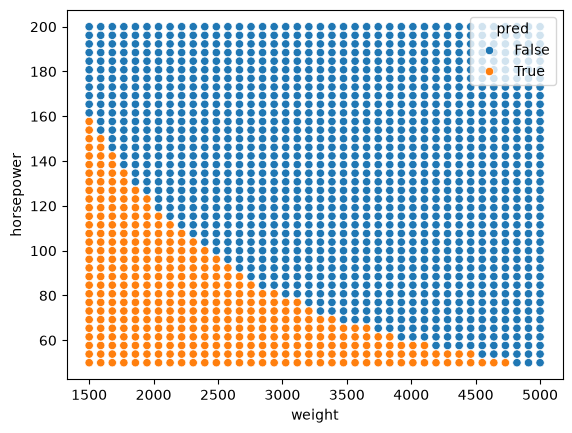

In [89]:
sns.scatterplot(
    x="weight",
    y="horsepower",
    hue="pred",
    data=df_fake
)